# Customer Segmentation with K-Means

**Business question:** our customers are not all the same. Which groups exist, and how should marketing talk to each one?

This notebook rebuilds my Digital Skola *Conqueror Project 2*: clean the data, choose the number of clusters,
segment 2,000 customers with K-Means, and turn the clusters into personas with marketing actions.

**Data:** 2,000 customers, 7 attributes: sex, marital status, age, education, income, occupation and settlement size
(`data/customer_segmentation.csv`, a public teaching dataset).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load and check the data

In [2]:
raw = pd.read_csv("data/customer_segmentation.csv")
print(raw.shape, "| missing values:", raw.isna().sum().sum(), "| duplicates:", raw.duplicated().sum())
raw.head()

(2000, 8) | missing values: 0 | duplicates: 0


,ID,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
0,100000001,0,0,67,2,124670,1,2
1,100000002,1,1,22,1,150773,1,2
2,100000003,0,0,49,1,89210,0,0
3,100000004,0,0,45,1,171565,1,1
4,100000005,0,0,53,1,149031,1,1


In [3]:
# Codes follow the dataset legend.
LEGEND = {
    "Sex": {0: "Male", 1: "Female"},
    "Marital status": {0: "Single", 1: "Non-single"},
    "Education": {0: "Other/unknown", 1: "High school", 2: "University", 3: "Graduate"},
    "Occupation": {0: "Unemployed/unskilled", 1: "Skilled employee", 2: "Management/self-employed"},
    "Settlement size": {0: "Small city", 1: "Mid-sized city", 2: "Big city"},
}
features = raw.drop(columns="ID")
labels = features.copy()
for col, mapping in LEGEND.items():
    labels[col] = labels[col].map(mapping)
features.describe().round(1)

,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
count,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0
mean,0.5,0.5,35.9,1.0,120954.4,0.8,0.7
std,0.5,0.5,11.7,0.6,38108.8,0.6,0.8
min,0.0,0.0,18.0,0.0,35832.0,0.0,0.0
25%,0.0,0.0,27.0,1.0,97663.2,0.0,0.0
50%,0.0,0.0,33.0,1.0,115548.5,1.0,1.0
75%,1.0,1.0,42.0,1.0,138072.2,1.0,1.0
max,1.0,1.0,76.0,3.0,309364.0,2.0,2.0


## 2. Explore the customers

Correlation age vs income: 0.34


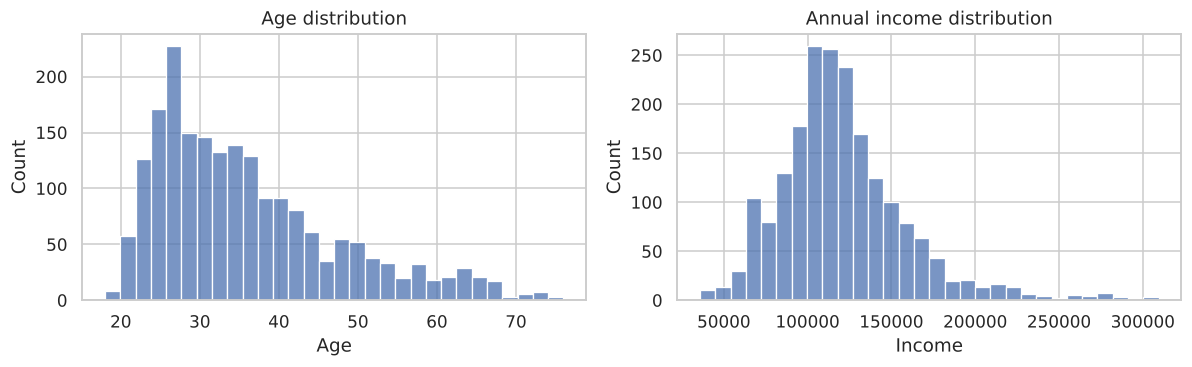

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(features["Age"], bins=30, ax=axes[0], color="#4C72B0")
axes[0].set_title("Age distribution")
sns.histplot(features["Income"], bins=30, ax=axes[1], color="#4C72B0")
axes[1].set_title("Annual income distribution")
plt.tight_layout()
print("Correlation age vs income:", round(features["Age"].corr(features["Income"]), 2))

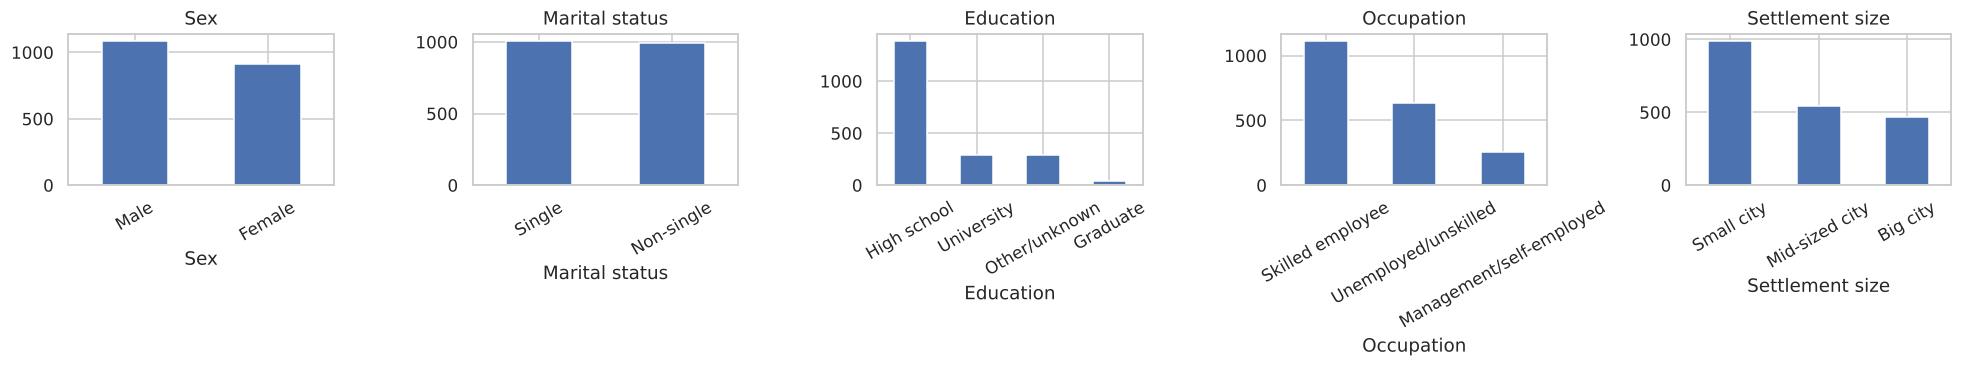

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, col in zip(axes, LEGEND):
    labels[col].value_counts().plot(kind="bar", ax=ax, color="#4C72B0", rot=30)
    ax.set_title(col)
plt.tight_layout()

Most customers are in their late 20s to 40s, earn around 120,000 a year, finished high school and work as skilled employees.
Age and income are moderately correlated (0.34). This is not enough to separate groups by eye, so clustering is used.

## 3. How many segments?

All seven attributes are standardised so that income (in the hundreds of thousands) does not dominate the
coded variables. Two checks are used: the **elbow** of the within-cluster error, and the **silhouette score**.

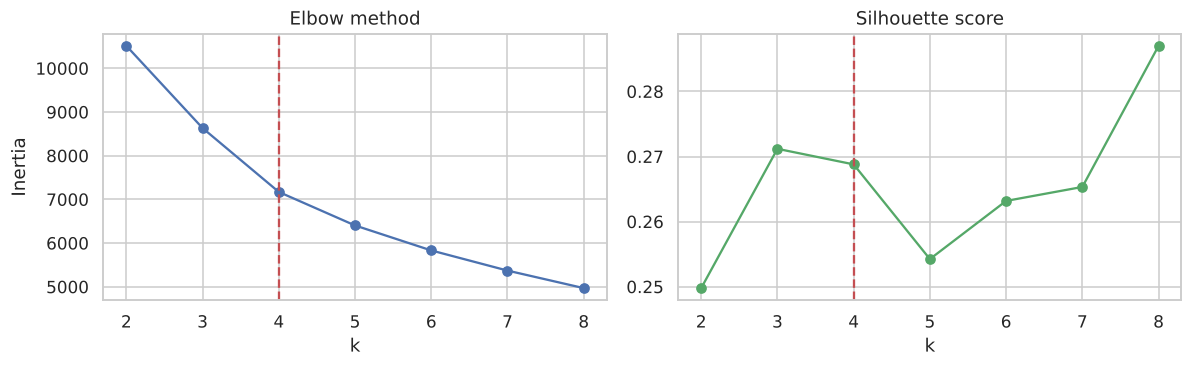

,inertia,silhouette
k,,
2,10514.0,0.250
3,8632.0,0.271
4,7170.0,0.269
5,6403.0,0.254
6,5831.0,0.263
7,5370.0,0.265
8,4969.0,0.287


In [6]:
X = StandardScaler().fit_transform(features)
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(list(ks), inertia, marker="o"); axes[0].set(title="Elbow method", xlabel="k", ylabel="Inertia")
axes[1].plot(list(ks), silhouette, marker="o", color="#55A868"); axes[1].set(title="Silhouette score", xlabel="k")
axes[0].axvline(4, color="#C44E52", ls="--"); axes[1].axvline(4, color="#C44E52", ls="--")
plt.tight_layout()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia), "silhouette": np.round(silhouette, 3)}).set_index("k")

The elbow bends around **k = 4**. Silhouette scores are close between 3 and 7 (0.25–0.29), so the data has no
single "natural" k. Four segments were chosen because they are distinct enough to describe and few enough for
a marketing team to run separate campaigns.

## 4. Build the segments

In [7]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X)
labels["Cluster"] = kmeans.labels_
features["Cluster"] = kmeans.labels_

profile = features.groupby("Cluster").agg(
    customers=("Age", "size"),
    avg_age=("Age", "mean"),
    avg_income=("Income", "mean"),
    share_female=("Sex", "mean"),
    share_non_single=("Marital status", "mean"),
)
profile["share_of_base"] = profile["customers"] / profile["customers"].sum()
profile.round(2)

,customers,avg_age,avg_income,share_female,share_non_single,share_of_base
Cluster,,,,,,
0,705,28.96,105759.12,0.85,1.00,0.35
1,570,35.64,141218.25,0.03,0.17,0.28
2,462,35.58,97859.85,0.35,0.02,0.23
3,263,55.70,158338.42,0.50,0.69,0.13


In [8]:
def mix(col):
    return pd.crosstab(labels["Cluster"], labels[col], normalize="index").mul(100).round(0)

for col in ["Education", "Occupation", "Settlement size"]:
    print(f"\n{col} (% of each cluster)")
    print(mix(col).to_string())


Education (% of each cluster)
Education  Graduate  High school  Other/unknown  University
Cluster                                                    
0               0.0         93.0            0.0         7.0
1               0.0         73.0           27.0         0.0
2               0.0         67.0           29.0         4.0
3              14.0          1.0            0.0        86.0

Occupation (% of each cluster)
Occupation  Management/self-employed  Skilled employee  Unemployed/unskilled
Cluster                                                                     
0                                2.0              60.0                  38.0
1                               29.0              69.0                   2.0
2                                0.0              33.0                  67.0
3                               29.0              56.0                  16.0

Settlement size (% of each cluster)
Settlement size  Big city  Mid-sized city  Small city
Cluster                 

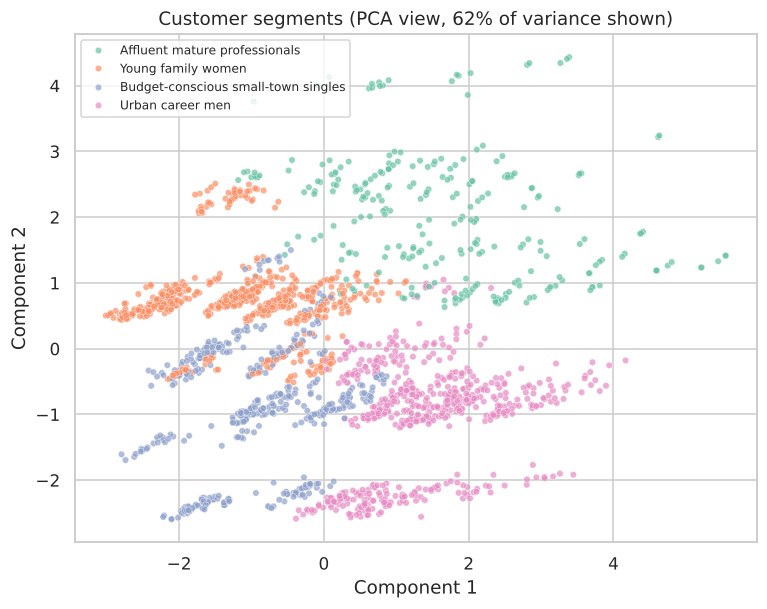

In [9]:
# Name the clusters from their profiles (checked against the tables above).
PERSONAS = {
    0: "Young family women",
    1: "Urban career men",
    2: "Budget-conscious small-town singles",
    3: "Affluent mature professionals",
}
assert profile.loc[3, "avg_age"] > 50 and profile.loc[0, "share_non_single"] > 0.9
labels["Persona"] = labels["Cluster"].map(PERSONAS)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pts = pca.fit_transform(X)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=pts[:, 0], y=pts[:, 1], hue=labels["Persona"], s=18, alpha=0.7, palette="Set2")
plt.title(f"Customer segments (PCA view, {pca.explained_variance_ratio_.sum():.0%} of variance shown)")
plt.xlabel("Component 1"); plt.ylabel("Component 2")
plt.legend(title="", fontsize=8, loc="best")

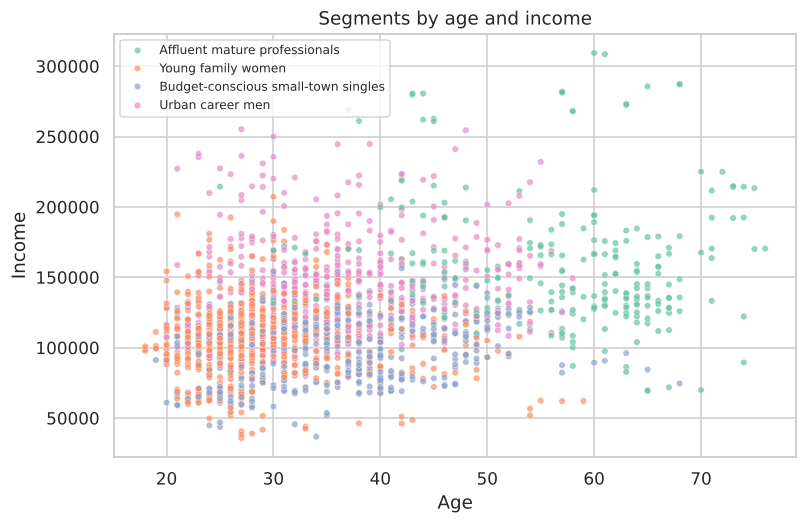

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=labels, x="Age", y="Income", hue="Persona", s=18, alpha=0.7, palette="Set2")
plt.title("Segments by age and income")
plt.legend(title="", fontsize=8)

## 5. Personas and marketing actions

| Segment | Share | Who they are | Suggested approach |
| --- | --- | --- | --- |
| **Young family women** | 35% | Around 29, almost all non-single, 85% women, high-school educated, mostly in small cities, mid income (~106k) | Family bundles, instalment plans, social-media and community channels |
| **Urban career men** | 28% | Around 36, 97% men, mostly single, skilled or management roles, mid/big cities, high income (~141k) | Premium and convenience products, time-saving services, digital and app-first channels |
| **Budget-conscious small-town singles** | 23% | Around 36, single, 96% in small cities, two-thirds unemployed or unskilled, lowest income (~98k) | Entry-level and value products, promotions and discounts, local partners |
| **Affluent mature professionals** | 13% | Around 56, university or graduate degree, highest income (~158k), spread across city sizes | High-value products, loyalty and personal service, financial or health-related offers |

**How to use it:** tag each customer with their segment in the CRM, track sales and response by segment, and test one tailored campaign per segment against a generic one.

*Limitations:* K-Means needs a chosen k, and silhouette scores (~0.27) show the segments overlap. The personas are a practical simplification, not hard boundaries.

In [11]:
summary = labels.groupby("Persona").agg(customers=("Age", "size"), avg_age=("Age", "mean"),
                                       avg_income=("Income", "mean")).round(0)
summary["share"] = (summary["customers"] / summary["customers"].sum()).round(2)
summary.sort_values("customers", ascending=False)

,customers,avg_age,avg_income,share
Persona,,,,
Young family women,705,29.0,105759.0,0.35
Urban career men,570,36.0,141218.0,0.28
Budget-conscious small-town singles,462,36.0,97860.0,0.23
Affluent mature professionals,263,56.0,158338.0,0.13
